# Lab 1 - Microstates of a system of coins (Person A: questions 1a, 1b)

Runs the code in `src/microstates.py`, its tests and `main.py`. Use **Run All** in VS Code with the `statphys_lab1` kernel.

## Setup
Adds the repo root to the path so `src` can be imported from `notebooks/`.

In [3]:
import subprocess
import sys
from math import comb
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np

from src.microstates import (
    benchmark_enumeration,
    count_heads,
    list_microstates_by_macrostate,
    macrostate_histogram,
    macrostate_histogram_fast,
    microstates,
    state_to_string,
)

print("Repo root:", ROOT)

Repo root: c:\claude\Lab1_stats


## Unit tests
Runs `pytest` on `tests/` (same as typing `pytest` in the terminal).

In [4]:
result = subprocess.run([sys.executable, "-m", "pytest", "-v"], cwd=ROOT, capture_output=True, text=True)
print(result.stdout[-3000:])

============================= test session starts =============================
platform win32 -- Python 3.13.14, pytest-9.2.0, pluggy-1.7.0 -- C:\Users\usuario\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe
cachedir: .pytest_cache
rootdir: c:\claude\Lab1_stats
configfile: pytest.ini
testpaths: tests
collecting ... collected 19 items

tests/test_microstates.py::test_generator_yields_all_states_once PASSED  [  5%]
tests/test_microstates.py::test_generator_rejects_negative_n PASSED      [ 10%]
tests/test_microstates.py::test_count_heads PASSED                       [ 15%]
tests/test_microstates.py::test_state_to_string PASSED                   [ 21%]
tests/test_microstates.py::test_n7_matches_expected_multiplicities PASSED [ 26%]
tests/test_microstates.py::test_n7_listing_is_complete_and_correct PASSED [ 31%]
tests/test_microstates.py::test_histogram_matches_binomial[0] PASSED     [ 36%]
tests/test_microstates.py::test_histogram_matches_

## How the bitwise encoding works
Each integer `s` in $[0, 2^N)$ is one microstate: bit $i$ is coin $i$ (1 = heads). The number of heads $k$ is the number of 1-bits of `s`.

In [5]:
N = 3
for s in microstates(N):
    print(f"s = {s}  binary = {s:0{N}b}  coins = {state_to_string(s, N)}  heads = {count_heads(s)}")

s = 0  binary = 000  coins = TTT  heads = 0
s = 1  binary = 001  coins = HTT  heads = 1
s = 2  binary = 010  coins = THT  heads = 1
s = 3  binary = 011  coins = HHT  heads = 2
s = 4  binary = 100  coins = TTH  heads = 1
s = 5  binary = 101  coins = HTH  heads = 2
s = 6  binary = 110  coins = THH  heads = 2
s = 7  binary = 111  coins = HHH  heads = 3


## 1a: all $2^7 = 128$ microstates of $N = 7$ coins

In [6]:
N = 7
groups = list_microstates_by_macrostate(N)
print(f"{'macrostate':<22}{'# microstates':>14}")
for k, states in groups.items():
    print(f"{f'{k} heads, {N - k} tails':<22}{len(states):>14}")
print(f"{'total':<22}{sum(len(s) for s in groups.values()):>14}")

macrostate             # microstates
7 heads, 0 tails                   1
6 heads, 1 tails                   7
5 heads, 2 tails                  21
4 heads, 3 tails                  35
3 heads, 4 tails                  35
2 heads, 5 tails                  21
1 heads, 6 tails                   7
0 heads, 7 tails                   1
total                            128


In [7]:
for k, states in groups.items():
    print(f"{k} heads ({len(states)}): {', '.join(states)}\n")

7 heads (1): HHHHHHH

6 heads (7): HHHHHHT, HHHHHTH, HHHHTHH, HHHTHHH, HHTHHHH, HTHHHHH, THHHHHH

5 heads (21): HHHHHTT, HHHHTHT, HHHTHHT, HHTHHHT, HTHHHHT, THHHHHT, HHHHTTH, HHHTHTH, HHTHHTH, HTHHHTH, THHHHTH, HHHTTHH, HHTHTHH, HTHHTHH, THHHTHH, HHTTHHH, HTHTHHH, THHTHHH, HTTHHHH, THTHHHH, TTHHHHH

4 heads (35): HHHHTTT, HHHTHTT, HHTHHTT, HTHHHTT, THHHHTT, HHHTTHT, HHTHTHT, HTHHTHT, THHHTHT, HHTTHHT, HTHTHHT, THHTHHT, HTTHHHT, THTHHHT, TTHHHHT, HHHTTTH, HHTHTTH, HTHHTTH, THHHTTH, HHTTHTH, HTHTHTH, THHTHTH, HTTHHTH, THTHHTH, TTHHHTH, HHTTTHH, HTHTTHH, THHTTHH, HTTHTHH, THTHTHH, TTHHTHH, HTTTHHH, THTTHHH, TTHTHHH, TTTHHHH

3 heads (35): HHHTTTT, HHTHTTT, HTHHTTT, THHHTTT, HHTTHTT, HTHTHTT, THHTHTT, HTTHHTT, THTHHTT, TTHHHTT, HHTTTHT, HTHTTHT, THHTTHT, HTTHTHT, THTHTHT, TTHHTHT, HTTTHHT, THTTHHT, TTHTHHT, TTTHHHT, HHTTTTH, HTHTTTH, THHTTTH, HTTHTTH, THTHTTH, TTHHTTH, HTTTHTH, THTTHTH, TTHTHTH, TTTHHTH, HTTTTHH, THTTTHH, TTHTTHH, TTTHTHH, TTTTHHH

2 heads (21): HHTTTTT, HTHTTTT, THHTTTT, 

## Check: the enumeration gives the binomial coefficients $\Omega(N,k) = \binom{N}{k}$

In [8]:
for N in [5, 7, 10, 16]:
    omega = macrostate_histogram(N)
    print(f"N = {N:2d}: {omega}  matches comb: {omega == [comb(N, k) for k in range(N + 1)]}  sum = 2^{N}: {sum(omega) == 2**N}")

N =  5: [1, 5, 10, 10, 5, 1]  matches comb: True  sum = 2^5: True
N =  7: [1, 7, 21, 35, 35, 21, 7, 1]  matches comb: True  sum = 2^7: True
N = 10: [1, 10, 45, 120, 210, 252, 210, 120, 45, 10, 1]  matches comb: True  sum = 2^10: True
N = 16: [1, 16, 120, 560, 1820, 4368, 8008, 11440, 12870, 11440, 8008, 4368, 1820, 560, 120, 16, 1]  matches comb: True  sum = 2^16: True


## 1b: pure-Python loop vs numpy (chunked) version

In [9]:
for N in [16, 18, 20]:
    t_py, s_py, _ = benchmark_enumeration(N, repeats=3, fast=False)
    t_np, s_np, _ = benchmark_enumeration(N, repeats=3, fast=True)
    print(f"N = {N}: Python {t_py:.3f} +/- {s_py:.3f} s, numpy {t_np:.4f} +/- {s_np:.4f} s, speed-up x{t_py / t_np:.0f}")

N = 16: Python 0.020 +/- 0.003 s, numpy 0.0003 +/- 0.0003 s, speed-up x60
N = 18: Python 0.066 +/- 0.004 s, numpy 0.0016 +/- 0.0011 s, speed-up x40
N = 20: Python 0.254 +/- 0.013 s, numpy 0.0104 +/- 0.0009 s, speed-up x24


## 1b: enumeration time and memory vs $N$
Each run is repeated 3 times (mean $\pm$ std). Peak RAM measured with `tracemalloc`.

In [10]:
ns, means, stds, rams = [], [], [], []
print(f"{'N':>3}{'2^N':>14}{'time (s)':>22}{'peak RAM (MiB)':>16}")
for N in range(10, 27, 2):
    mean, std, ram = benchmark_enumeration(N, repeats=3)
    ns.append(N); means.append(mean); stds.append(std); rams.append(ram)
    print(f"{N:>3}{2**N:>14}{f'{mean:.4f} +/- {std:.4f}':>22}{ram:>16.2f}")

  N           2^N              time (s)  peak RAM (MiB)
 10          1024     0.0010 +/- 0.0017            0.02
 12          4096     0.0001 +/- 0.0000            0.07
 14         16384     0.0001 +/- 0.0001            0.27
 16         65536     0.0005 +/- 0.0002            1.06
 18        262144     0.0022 +/- 0.0002            4.25
 20       1048576     0.0134 +/- 0.0008           17.00
 22       4194304     0.0492 +/- 0.0019           68.00
 24      16777216     0.1866 +/- 0.0124           68.00
 26      67108864     0.7189 +/- 0.0726           68.00


slope b = 0.730 (theory ln 2 = 0.693)
extrapolated largest N in 5 min: 34.1


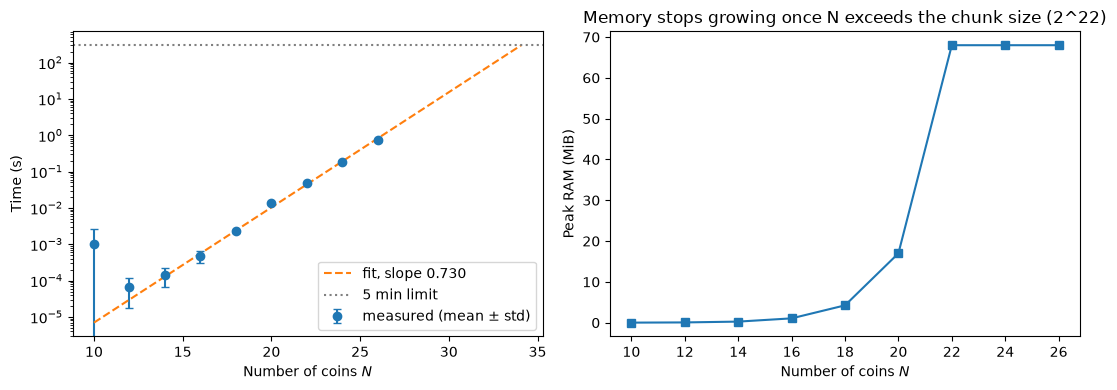

In [11]:
ns_arr, means_arr = np.array(ns), np.array(means)
fit = ns_arr >= 16
b, a = np.polyfit(ns_arr[fit], np.log(means_arr[fit]), 1)
n_limit = (np.log(300) - a) / b
print(f"slope b = {b:.3f} (theory ln 2 = {np.log(2):.3f})")
print(f"extrapolated largest N in 5 min: {n_limit:.1f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.errorbar(ns, means, yerr=stds, fmt="o", capsize=3, label="measured (mean ± std)")
n_line = np.linspace(min(ns), n_limit, 100)
ax1.plot(n_line, np.exp(a + b * n_line), "--", label=f"fit, slope {b:.3f}")
ax1.axhline(300, color="gray", linestyle=":", label="5 min limit")
ax1.set_yscale("log"); ax1.set_xlabel("Number of coins $N$"); ax1.set_ylabel("Time (s)"); ax1.legend()
ax2.plot(ns, rams, "s-")
ax2.set_xlabel("Number of coins $N$"); ax2.set_ylabel("Peak RAM (MiB)")
ax2.set_title("Memory stops growing once N exceeds the chunk size (2^22)")
fig.tight_layout()
plt.show()

## Run `main.py`
Same as `python main.py` in the terminal: prints 1a and 1b and writes the figure to `report/figures/`.

In [12]:
result = subprocess.run([sys.executable, "main.py"], cwd=ROOT, capture_output=True, text=True)
print(result.stdout, result.stderr)

Statistical Physics - Lab 1: Microstates of a System of Coins

=== 1a: microstates of N = 7 coins ===
macrostate             # microstates
7 heads, 0 tails                   1
6 heads, 1 tails                   7
5 heads, 2 tails                  21
4 heads, 3 tails                  35
3 heads, 4 tails                  35
2 heads, 5 tails                  21
1 heads, 6 tails                   7
0 heads, 7 tails                   1
total                            128  (2^7 = 128)
Full list written to c:\claude\Lab1_stats\report\microstates_N7.txt

=== 1b: enumeration time vs N (3 repeats each) ===
  N             2^N              time (s)  peak RAM (MiB)
 10            1024     0.0000 +/- 0.0000            0.02
 12            4096     0.0001 +/- 0.0000            0.07
 14           16384     0.0001 +/- 0.0001            0.27
 16           65536     0.0006 +/- 0.0004            1.06
 18          262144     0.0011 +/- 0.0005            4.25
 20         1048576     0.0099 +/- 0.0004      

## Optional: measure the real 5-minute limit
Slow (several minutes). Change `False` to `True` to run it.

In [14]:
RUN_FIND_LIMIT = True
if RUN_FIND_LIMIT:
    result = subprocess.run([sys.executable, "main.py", "--find-limit"], cwd=ROOT, capture_output=True, text=True)
    print(result.stdout, result.stderr)

Statistical Physics - Lab 1: Microstates of a System of Coins

=== 1a: microstates of N = 7 coins ===
macrostate             # microstates
7 heads, 0 tails                   1
6 heads, 1 tails                   7
5 heads, 2 tails                  21
4 heads, 3 tails                  35
3 heads, 4 tails                  35
2 heads, 5 tails                  21
1 heads, 6 tails                   7
0 heads, 7 tails                   1
total                            128  (2^7 = 128)
Full list written to c:\claude\Lab1_stats\report\microstates_N7.txt

=== 1b: enumeration time vs N (3 repeats each) ===
  N             2^N              time (s)  peak RAM (MiB)
 10            1024     0.0002 +/- 0.0003            0.02
 12            4096     0.0000 +/- 0.0000            0.07
 14           16384     0.0002 +/- 0.0001            0.27
 16           65536     0.0005 +/- 0.0002            1.06
 18          262144     0.0013 +/- 0.0007            4.25
 20         1048576     0.0094 +/- 0.0007      